# LED optics and Monte Carlo illuminance

An LED is a small, flat, very bright source that emits into a whole
hemisphere. Almost every LED luminaire therefore does one of two jobs. It
either spreads the light evenly over a surface (a ceiling panel, a
backlight, a row of street lights), or it gathers it into a beam (a
spotlight, a torch, a headlamp). This notebook covers both, with the tool
that lighting design runs on: Monte Carlo ray tracing, where every ray
carries $\Phi/N$ of the flux and the illuminance is counted in bins.

The sections are:

1. LED emission patterns $I_0\cos^m\theta$, and a simulated goniometer,
2. the illuminance on a plane, how Monte Carlo noise and binning bias
   trade off, and why quasi-random (Sobol) rays converge faster,
3. the photometric distance: when the inverse square law may be used,
4. LED arrays for even illumination: two LEDs, large arrays and the edge
   of a finite one,
5. collimating an LED with a lens, a parabolic reflector and both (the
   principle of a TIR collimator), checked against the brightness theorem.

The functions are in `pyoptics.illumination`: `cos_power_directions()`,
`cos_power_exponent()`, `cos_power_flux()`, `irradiance_map()`,
`intensity_profile()`, `point_source_irradiance()`,
`disk_irradiance_on_axis()` and `paraboloid_reflector()`. The ray trace
of the lens uses `pyoptics.raytrace`. The code counts in radiometric terms
(W, W/m², W/sr). Every LED here emits 100 lm, so the same numbers read as
lumens, lux and candela.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc

from pyoptics import illumination as il
from pyoptics import raytrace as rt
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(88)

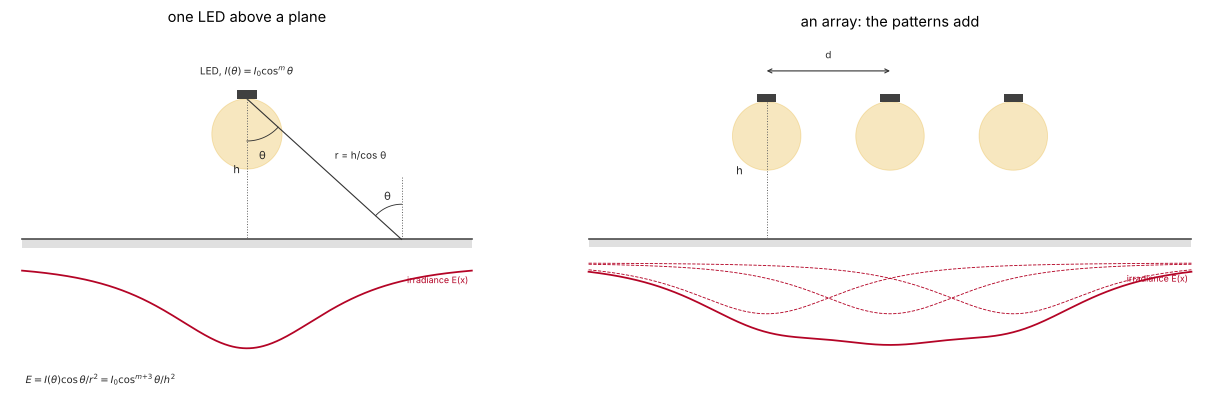

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
sketch.led_above_plane(ax[0], title="one LED above a plane")
sketch.led_above_plane(ax[1], n_leds=3, spacing=0.9, title="an array: the patterns add")
plt.show()

## 1. Emission patterns

A bare LED die is close to a Lambertian emitter: constant radiance, so the
intensity falls as $\cos\theta$. Domes and primary lenses narrow the
pattern, which is usually written as

$$I(\theta) = I_0\cos^m\theta,\qquad m = -\frac{\ln 2}{\ln\cos\theta_{1/2}},\qquad \Phi = \frac{2\pi I_0}{m + 1},$$

with the half angle $\theta_{1/2}$ at half intensity ($m = 1$ is the
Lambertian 60°). To sample it, note that the flux into the polar angle
$\theta$ goes as $\cos^m\theta\sin\theta$. So
$\cos\theta = u^{1/(m+1)}$ for a uniform random number $u$, and the
azimuth is uniform.

A goniometer measures the intensity by moving a detector around the
source in its far field. The Monte Carlo version bins the ray directions
into rings of solid angle $2\pi(\cos\theta_1 - \cos\theta_2)$.

In [3]:
PHI = 100.0                                   # lm, flux of every LED in this notebook
half_angles = np.deg2rad([60.0, 30.0, 15.0])
ms = il.cos_power_exponent(half_angles)
for th, m in zip(half_angles, ms):
    I0 = PHI*(m + 1)/(2*np.pi)
    print("half angle {:2.0f} deg: m = {:5.2f}, on-axis intensity {:6.1f} cd for {:.0f} lm".format(np.degrees(th), m, I0, PHI))
# a simulated goniometer: rays from each pattern binned into rings of solid angle
edges = np.deg2rad(np.linspace(0, 90, 46))
gonio = {}
for m in ms:
    d = il.cos_power_directions(1_000_000, m, rng=rng)
    gonio[m] = il.intensity_profile(d, PHI/len(d), edges)
    I, th = gonio[m]
    I_th = PHI*(m + 1)/(2*np.pi)*np.cos(th)**m
    print("m = {:5.2f}: max |I_MC - I|/I_0 = {:.3f}, flux from the profile {:.2f} lm".format(
        m, np.max(np.abs(I - I_th))/I_th[0], np.sum(I*2*np.pi*(np.cos(edges[:-1]) - np.cos(edges[1:])))))

half angle 60 deg: m =  1.00, on-axis intensity   31.8 cd for 100 lm
half angle 30 deg: m =  4.82, on-axis intensity   92.6 cd for 100 lm
half angle 15 deg: m = 19.99, on-axis intensity  334.1 cd for 100 lm
m =  1.00: max |I_MC - I|/I_0 = 0.015, flux from the profile 100.00 lm


m =  4.82: max |I_MC - I|/I_0 = 0.016, flux from the profile 100.00 lm
m = 19.99: max |I_MC - I|/I_0 = 0.005, flux from the profile 100.00 lm


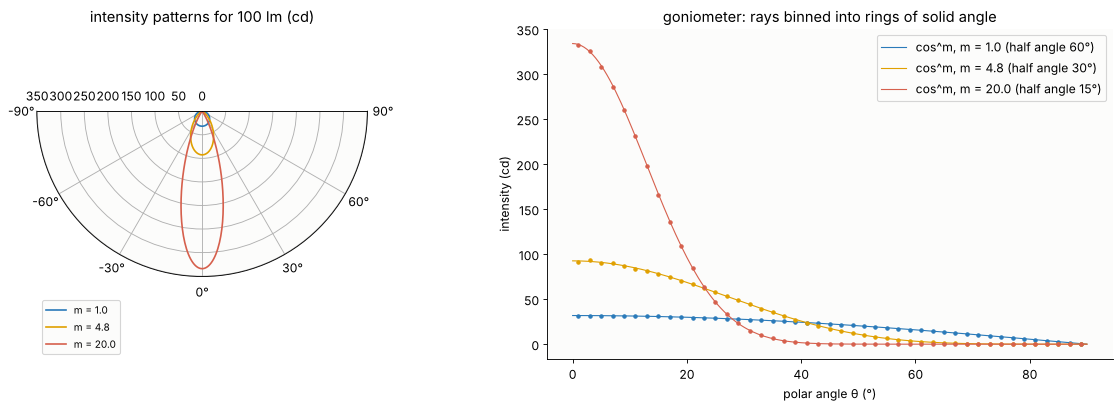

In [4]:
fig = plt.figure(figsize=(15, 5), layout="constrained")
a0 = fig.add_subplot(1, 2, 1, projection="polar")
a1 = fig.add_subplot(1, 2, 2)
tt = np.linspace(-np.pi/2, np.pi/2, 361)
for m, c in zip(ms, (BLUE, ORANGE, RED)):
    I0 = PHI*(m + 1)/(2*np.pi)
    a0.plot(tt, I0*np.cos(tt)**m, color=c, label="m = {:.1f}".format(m))
    I, th = gonio[m]
    a1.plot(np.degrees(th), I, "o", ms=3, color=c)
    a1.plot(np.degrees(tt[tt >= 0]), I0*np.cos(tt[tt >= 0])**m, color=c, lw=1,
            label="cos^m, m = {:.1f} (half angle {:.0f}°)".format(m, np.degrees(np.arccos(0.5**(1/m)))))
a0.set_theta_zero_location("S")
a0.set_thetamin(-90)
a0.set_thetamax(90)
a0.set_title("intensity patterns for 100 lm (cd)")
a0.legend(loc="lower left", fontsize=9)
a1.set_xlabel("polar angle θ (°)")
a1.set_ylabel("intensity (cd)")
a1.set_title("goniometer: rays binned into rings of solid angle")
a1.legend()
plt.show()

For the same 100 lm the on-axis intensity grows from 31.8 cd (Lambertian)
through 92.6 cd (30°) to 334 cd (15°, $m = 20$). The simulated goniometer
reproduces each pattern to within 1.6 % of $I_0$ with a million rays, and
integrating its rings gives back the 100 lm.

## 2. Illuminance on a plane: noise, bias and quasi-random rays

An LED at the height $h$ above a floor lights a point at the angle
$\theta$ from the distance $r = h/\cos\theta$, and the floor is tilted by
$\theta$ against the ray. So

$$E = \frac{I(\theta)\cos\theta}{r^2} = \frac{I_0\cos^{m+3}\theta}{h^2}.$$

The Monte Carlo estimate of a bin is (number of rays in it) × $\Phi/N$ /
(bin area). A bin that receives $n$ rays has a Poisson error of
$1/\sqrt n$. Smaller bins resolve more detail but collect fewer rays.
Larger bins average the illuminance over their area and so blur it, a
bias that grows as the square of the bin width times the curvature of $E$.

Pseudo-random numbers are not the only choice. A **quasi-random**
sequence, here a scrambled Sobol sequence (`scipy.stats.qmc`), fills the
unit square evenly by construction, so the rays fill phase space without
the clumps and gaps of random sampling.

In [5]:
H2 = 1.0                                      # m: one LED 1 m above the floor
M2 = ms[1]                                    # 30 deg half angle
I02 = PHI*(M2 + 1)/(2*np.pi)
X2 = 1.0
def floor_hits(N, u=None, m=M2):
    d = il.cos_power_directions(N, m, rng=rng, u=u)
    return d[:, :2]/d[:, 2:3]*H2
N2 = 2_000_000
E2, x2, y2 = il.irradiance_map(floor_hits(N2), PHI/N2, 50, [(-X2, X2)]*2)
E2_th = il.point_source_irradiance(x2[:, None], y2[None, :], H2, I02, M2)
n_bin = E2*(x2[1] - x2[0])*(y2[1] - y2[0])/(PHI/N2)     # rays per bin
rel = (E2 - E2_th)/E2_th
print("on-axis illuminance: {:.1f} lux (I_0/h^2 = {:.1f})".format(E2[25, 25], I02/H2**2))
print("rms of (E_MC - E)/E: {:.4f}; predicted from the ray counts, rms of 1/sqrt(n_bin): {:.4f}".format(
    np.sqrt(np.mean(rel**2)), np.sqrt(np.mean(1/n_bin))))
# bias against noise: error of the bin value against E at the bin centre, for a fixed number of rays
N_bv = 1_000_000
P_bv = floor_hits(N_bv)
bins_list = np.array([4, 6, 10, 16, 24, 40, 64, 100, 160, 250])
err_bv, noise_bv, bias_bv = [], [], []
xs_f = np.linspace(-0.5, 0.5, 2001)
for nb in bins_list:
    E, x, y = il.irradiance_map(P_bv, PHI/N_bv, nb, [(-0.5, 0.5)]*2)
    E_c = il.point_source_irradiance(x[:, None], y[None, :], H2, I02, M2)
    err_bv.append(np.sqrt(np.mean((E/E_c - 1)**2)))
    noise_bv.append(np.sqrt(np.mean(PHI/N_bv/(E_c*(x[1] - x[0])**2))))
    # bias: the bin average of the exact E against its centre value (1D average in x and y)
    w = 1.0/nb
    sub = np.linspace(-w/2, w/2, 21)
    E_avg = np.mean([il.point_source_irradiance(x[:, None] + sx, y[None, :] + sy, H2, I02, M2)
                     for sx in sub for sy in sub], axis=0)
    bias_bv.append(np.sqrt(np.mean((E_avg/E_c - 1)**2)))
err_bv, noise_bv, bias_bv = map(np.array, (err_bv, noise_bv, bias_bv))
for nb, e, nz, bs in zip(bins_list, err_bv, noise_bv, bias_bv):
    print("{:3d} x {:3d} bins of {:5.1f} mm: rms error {:.4f} (noise {:.4f}, bias {:.4f})".format(nb, nb, 1e3/nb, e, nz, bs))
# pseudo-random against quasi-random (scrambled Sobol) sampling: error against the bin-averaged exact map
nb_q = 20
sub = np.linspace(-0.5, 0.5, 17)[:-1] + 1/32
xq = (np.arange(nb_q) + 0.5)/nb_q*2*X2 - X2
E_binavg = np.mean([il.point_source_irradiance(xq[:, None] + sx*2*X2/nb_q, xq[None, :] + sy*2*X2/nb_q, H2, I02, M2)
                    for sx in sub for sy in sub], axis=0)
Ns = 2**np.arange(12, 23, 2)
conv = {"pseudo-random": [], "Sobol": []}
for N in Ns:
    for kind in conv:
        errs = []
        for seed in range(4):
            u = qmc.Sobol(2, scramble=True, seed=seed).random(N) if kind == "Sobol" else None
            E, _, _ = il.irradiance_map(floor_hits(N, u=u), PHI/N, nb_q, [(-X2, X2)]*2)
            errs.append(np.sqrt(np.mean((E/E_binavg - 1)**2)))
        conv[kind].append(np.mean(errs))
for N, a, b in zip(Ns, conv["pseudo-random"], conv["Sobol"]):
    print("N = {:8d}: rms error pseudo-random {:.4f}, Sobol {:.5f} ({:.0f}x smaller)".format(N, a, b, a/b))
slope = {k: np.polyfit(np.log(Ns), np.log(v), 1)[0] for k, v in conv.items()}
print("convergence exponents: pseudo-random {:.2f}, Sobol {:.2f}".format(slope["pseudo-random"], slope["Sobol"]))

on-axis illuminance: 93.5 lux (I_0/h^2 = 92.6)
rms of (E_MC - E)/E: 0.0606; predicted from the ray counts, rms of 1/sqrt(n_bin): 0.0592


  4 x   4 bins of 250.0 mm: rms error 0.0190 (noise 0.0056, bias 0.0203)
  6 x   6 bins of 166.7 mm: rms error 0.0118 (noise 0.0085, bias 0.0092)
 10 x  10 bins of 100.0 mm: rms error 0.0135 (noise 0.0143, bias 0.0033)
 16 x  16 bins of  62.5 mm: rms error 0.0213 (noise 0.0230, bias 0.0013)
 24 x  24 bins of  41.7 mm: rms error 0.0329 (noise 0.0345, bias 0.0006)
 40 x  40 bins of  25.0 mm: rms error 0.0581 (noise 0.0575, bias 0.0002)
 64 x  64 bins of  15.6 mm: rms error 0.0919 (noise 0.0920, bias 0.0001)
100 x 100 bins of  10.0 mm: rms error 0.1441 (noise 0.1438, bias 0.0000)
160 x 160 bins of   6.2 mm: rms error 0.2303 (noise 0.2300, bias 0.0000)
250 x 250 bins of   4.0 mm: rms error 0.3601 (noise 0.3594, bias 0.0000)


N =     4096: rms error pseudo-random 0.5021, Sobol 0.30677 (2x smaller)
N =    16384: rms error pseudo-random 0.2607, Sobol 0.10548 (2x smaller)
N =    65536: rms error pseudo-random 0.1292, Sobol 0.04111 (3x smaller)
N =   262144: rms error pseudo-random 0.0628, Sobol 0.01395 (4x smaller)
N =  1048576: rms error pseudo-random 0.0327, Sobol 0.00475 (7x smaller)
N =  4194304: rms error pseudo-random 0.0157, Sobol 0.00175 (9x smaller)
convergence exponents: pseudo-random -0.50, Sobol -0.75


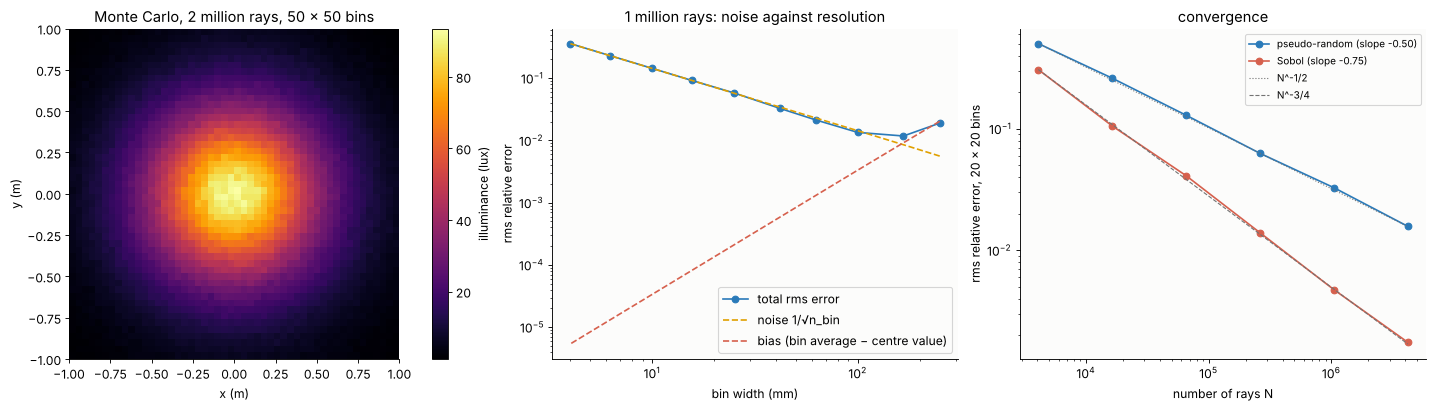

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5), layout="constrained")
im = ax[0].imshow(E2.T, extent=[-X2, X2, -X2, X2], origin="lower", cmap="inferno")
fig.colorbar(im, ax=ax[0], label="illuminance (lux)")
ax[0].set_xlabel("x (m)")
ax[0].set_ylabel("y (m)")
ax[0].set_title("Monte Carlo, 2 million rays, 50 × 50 bins")
ax[1].loglog(1e3/bins_list, err_bv, "o-", color=BLUE, label="total rms error")
ax[1].loglog(1e3/bins_list, noise_bv, "--", color=ORANGE, label="noise 1/√n_bin")
ax[1].loglog(1e3/bins_list, bias_bv, "--", color=RED, label="bias (bin average − centre value)")
ax[1].set_xlabel("bin width (mm)")
ax[1].set_ylabel("rms relative error")
ax[1].set_title("1 million rays: noise against resolution")
ax[1].legend()
for k, c in (("pseudo-random", BLUE), ("Sobol", RED)):
    ax[2].loglog(Ns, conv[k], "o-", color=c, label="{} (slope {:.2f})".format(k, slope[k]))
ax[2].loglog(Ns, conv["pseudo-random"][0]*(Ns/Ns[0])**-0.5, color=GREY, ls=":", lw=1, label="N^-1/2")
ax[2].loglog(Ns, conv["Sobol"][0]*(Ns/Ns[0])**-0.75, color=GREY, ls="--", lw=1, label="N^-3/4")
ax[2].set_xlabel("number of rays N")
ax[2].set_ylabel("rms relative error, 20 × 20 bins")
ax[2].set_title("convergence")
ax[2].legend(fontsize=9)
plt.show()

Left: the LED with the 30° half angle, 1 m above the floor, 2 million rays.
The rms deviation from the exact map is 6.1 %, just what the ray counts
predict (5.9 %). Middle: with a million rays, the error falls with the
bin size at first, because the bias drops, then grows, because the noise
rises. The best bins (17 cm here) give 1.2 %. Below 10 cm the noise
dominates. Right: the error of a 20 × 20 map against the exact bin
averages. Pseudo-random rays converge as $N^{-1/2}$. Sobol rays converge
as $N^{-0.75}$, which is the expected rate for bin counts (integrals of a
discontinuous function in two dimensions, $N^{-1/2 - 1/(2d)}$). At 4
million rays the error is 9 times smaller, worth 80 times more
pseudo-random rays. The scrambling keeps the estimate unbiased, and
repeated scrambles give its error bar.

## 3. The photometric distance

The inverse square law $E = I/d^2$ treats the source as a point. For a
Lambertian disk of radius $a$ and radiance $L$, the illuminance on its
axis is exactly

$$E = \frac{\pi L a^2}{a^2 + d^2},$$

so the inverse square law overestimates it by the factor $1 + a^2/d^2$.
This is the origin of the "five times rule" of photometry: measure at
five source diameters or more, and the error stays below 1 %. Here a chip
on board (COB) LED, a disk of 20 mm diameter, is traced with 4 million
rays.

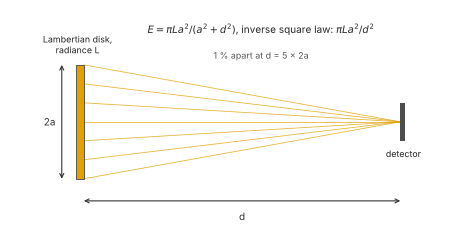

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8))
sketch.photometric_distance(ax)
plt.show()

In [8]:
A3 = 10.0                                     # mm, radius of a chip-on-board LED
L3 = PHI/(np.pi*np.pi*A3**2)                  # lm/(mm^2 sr): the radiance that gives 100 lm
N3 = 4_000_000
xy3 = il.disk_points(N3, A3, rng)
d3 = il.lambertian_directions(N3, rng=rng)
dists = A3*np.array([1, 2, 3, 5, 10, 20])
E3 = []
for dist in dists:
    P = xy3 + d3[:, :2]/d3[:, 2:3]*dist
    r0 = 0.05*dist
    E3.append(np.sum(np.hypot(P[:, 0], P[:, 1]) < r0)*PHI/N3/(np.pi*r0**2))
E3 = np.array(E3)
for dist, e in zip(dists, E3):
    ex = il.disk_irradiance_on_axis(L3, A3, dist)
    inv = np.pi*L3*A3**2/dist**2
    print("d = {:4.0f} mm = {:4.1f} diameters: MC {:.5f}, exact {:.5f}, inverse square {:.5f} lm/mm^2 (+{:.1%})".format(
        dist, dist/(2*A3), e, ex, inv, inv/ex - 1))

d =   10 mm =  0.5 diameters: MC 0.15954, exact 0.15915, inverse square 0.31831 lm/mm^2 (+100.0%)
d =   20 mm =  1.0 diameters: MC 0.06459, exact 0.06366, inverse square 0.07958 lm/mm^2 (+25.0%)
d =   30 mm =  1.5 diameters: MC 0.03149, exact 0.03183, inverse square 0.03537 lm/mm^2 (+11.1%)
d =   50 mm =  2.5 diameters: MC 0.01229, exact 0.01224, inverse square 0.01273 lm/mm^2 (+4.0%)
d =  100 mm =  5.0 diameters: MC 0.00311, exact 0.00315, inverse square 0.00318 lm/mm^2 (+1.0%)
d =  200 mm = 10.0 diameters: MC 0.00079, exact 0.00079, inverse square 0.00080 lm/mm^2 (+0.3%)


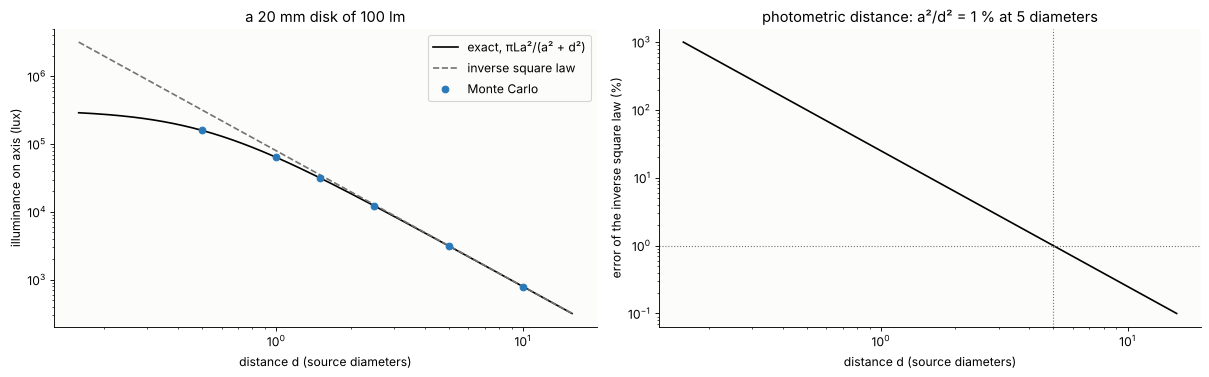

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
dd = A3*np.logspace(-0.5, 1.5, 200)
ax[0].loglog(dd/(2*A3), il.disk_irradiance_on_axis(L3, A3, dd)*1e6, color="k", label="exact, πLa²/(a² + d²)")
ax[0].loglog(dd/(2*A3), np.pi*L3*A3**2/dd**2*1e6, color=GREY, ls="--", label="inverse square law")
ax[0].loglog(dists/(2*A3), E3*1e6, "o", color=BLUE, label="Monte Carlo")
ax[0].set_xlabel("distance d (source diameters)")
ax[0].set_ylabel("illuminance on axis (lux)")
ax[0].set_title("a 20 mm disk of 100 lm")
ax[0].legend()
ax[1].loglog(dd/(2*A3), A3**2/dd**2*100, color="k")
ax[1].axhline(1, color=GREY, ls=":", lw=1)
ax[1].axvline(5, color=GREY, ls=":", lw=1)
ax[1].set_xlabel("distance d (source diameters)")
ax[1].set_ylabel("error of the inverse square law (%)")
ax[1].set_title("photometric distance: a²/d² = 1 % at 5 diameters")
plt.show()

The Monte Carlo illuminance follows the exact formula at every distance.
The inverse square law is 100 % off at half a diameter, 25 % at one
diameter, 4 % at 2.5 and 1.0 % at five diameters. Section 5 shows that
the rule is about the size of the *emitting aperture*, not of the die: a
collimator is a large source.

## 4. LED arrays for even illumination

Two LEDs at the height $h$ and the spacing $d$ give the sum of two
$\cos^{m+3}$ profiles. The sum is flattest when its curvature vanishes
in the middle. With $u = x/h$, each profile goes as
$(1 + u^2)^{-(m+3)/2}$, whose second derivative vanishes at
$u^2 = 1/(m + 4)$, so

$$d_\mathrm{flat} = \frac{2h}{\sqrt{m + 4}}.$$

For large square arrays the question becomes how far apart the LEDs may
be for a given uniformity. Here that is min/max ≥ 0.9 over the central
cell of a 21 × 21 array, which stands in for an infinite one. A finite
array also falls off at its edges, since the outer LEDs have no
neighbours beyond them. The last panel is a 6 × 6 Lambertian array,
traced with Sobol rays.

In [10]:
H4 = 1.0
def two_leds(x, d, m):
    return il.point_source_irradiance(x - d/2, 0, H4, 1, m) + il.point_source_irradiance(x + d/2, 0, H4, 1, m)
d_flat = {m: 2*H4/np.sqrt(m + 4) for m in ms}
for m in ms:
    print("m = {:5.2f}: two LEDs flattest at d = 2h/sqrt(m + 4) = {:.3f} h".format(m, d_flat[m]))
def cell_uniformity(d, m, n=21, k=41):
    """min/max of the illuminance over the central cell of an n x n square array (spacing d, height H4)."""
    c = (np.arange(n) - (n - 1)/2)*d
    u = np.linspace(-d/2, d/2, k)
    X, Y = np.meshgrid(u, u)
    E = sum(il.point_source_irradiance(X - cx, Y - cy, H4, 1, m) for cx in c for cy in c)
    return E.min()/E.max()
d_grid = np.linspace(0.3, 2.4, 43)
U4 = {m: np.array([cell_uniformity(d, m) for d in d_grid]) for m in ms}
d90 = {}
for m in ms:
    i = np.where(U4[m] >= 0.9)[0].max()
    d90[m] = np.interp(0.9, U4[m][i:i + 2][::-1], d_grid[i:i + 2][::-1])
    print("m = {:5.2f}: square array, min/max >= 0.9 up to d = {:.2f} h".format(m, d90[m]))
# a finite 6 x 6 array of Lambertian LEDs at that spacing, by Monte Carlo with quasi-random rays
m4, n4 = ms[0], 6
d4 = d90[m4]
c4 = (np.arange(n4) - (n4 - 1)/2)*d4
N4 = 2**18
E4 = 0
for k, (cx, cy) in enumerate((cx, cy) for cx in c4 for cy in c4):
        u = qmc.Sobol(2, scramble=True, seed=k).random(N4)
        d = il.cos_power_directions(N4, m4, u=u)
        P = d[:, :2]/d[:, 2:3]*H4 + [cx, cy]
        E, x4, y4 = il.irradiance_map(P, PHI/N4, 60, [(-3, 3)]*2)
        E4 = E4 + E
inner = (np.abs(x4[:, None]) < c4[-1]) & (np.abs(y4[None, :]) < c4[-1])
print("6 x 6 Lambertian array, d = {:.2f} h: min/max inside the array {:.2f}, mean {:.0f} lux; "
      "corner/centre {:.2f}".format(d4, E4[inner].min()/E4[inner].max(), E4[inner].mean(),
                                    E4[np.argmin(np.abs(x4 - c4[-1])), np.argmin(np.abs(y4 - c4[-1]))]/E4[30, 30]))

m =  1.00: two LEDs flattest at d = 2h/sqrt(m + 4) = 0.894 h
m =  4.82: two LEDs flattest at d = 2h/sqrt(m + 4) = 0.673 h
m = 19.99: two LEDs flattest at d = 2h/sqrt(m + 4) = 0.408 h


m =  1.00: square array, min/max >= 0.9 up to d = 1.15 h
m =  4.82: square array, min/max >= 0.9 up to d = 0.77 h
m = 19.99: square array, min/max >= 0.9 up to d = 0.44 h


6 x 6 Lambertian array, d = 1.15 h: min/max inside the array 0.67, mean 65 lux; corner/centre 0.75


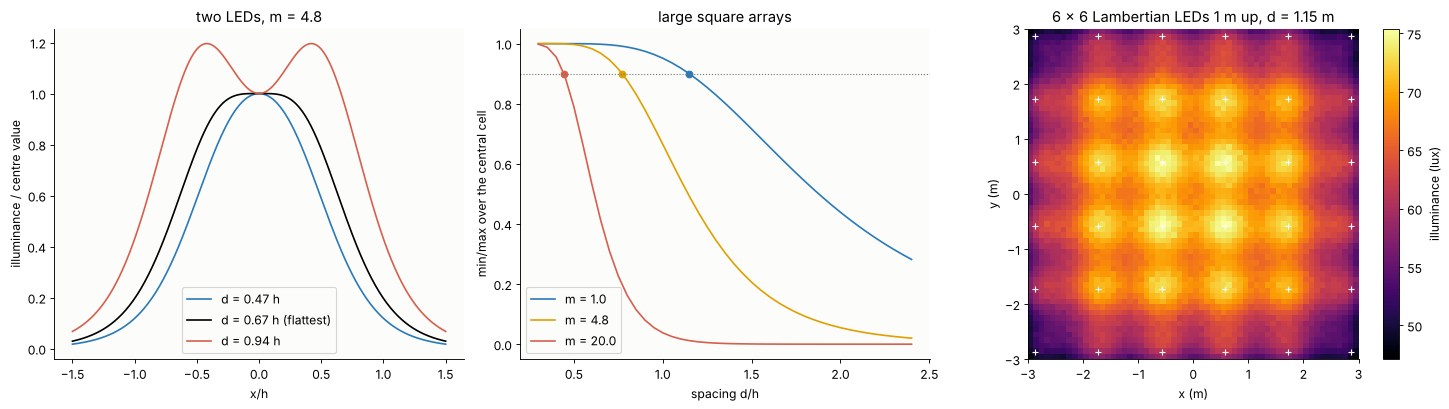

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5), layout="constrained")
xx = np.linspace(-1.5, 1.5, 400)
m = ms[1]
for f_d, c in ((0.7, BLUE), (1.0, "k"), (1.4, RED)):
    d = f_d*d_flat[m]
    E = two_leds(xx, d, m)
    ax[0].plot(xx, E/two_leds(0.0, d, m), color=c, label="d = {:.2f} h{}".format(d, " (flattest)" if f_d == 1 else ""))
ax[0].set_xlabel("x/h")
ax[0].set_ylabel("illuminance / centre value")
ax[0].set_title("two LEDs, m = {:.1f}".format(m))
ax[0].legend()
for m, c in zip(ms, (BLUE, ORANGE, RED)):
    ax[1].plot(d_grid, U4[m], color=c, label="m = {:.1f}".format(m))
    ax[1].plot(d90[m], 0.9, "o", color=c)
ax[1].axhline(0.9, color=GREY, ls=":", lw=1)
ax[1].set_xlabel("spacing d/h")
ax[1].set_ylabel("min/max over the central cell")
ax[1].set_title("large square arrays")
ax[1].legend()
im = ax[2].imshow(E4.T, extent=[-3, 3, -3, 3], origin="lower", cmap="inferno")
ax[2].plot(*np.meshgrid(c4, c4), "w+", ms=6)
fig.colorbar(im, ax=ax[2], label="illuminance (lux)")
ax[2].set_xlabel("x (m)")
ax[2].set_ylabel("y (m)")
ax[2].set_title("6 × 6 Lambertian LEDs 1 m up, d = {:.2f} m".format(d4))
plt.show()

Two LEDs are flattest at 0.89 $h$ (Lambertian), 0.67 $h$ (30°) and
0.41 $h$ (15°). Closer, the sum has a single peak. Further apart it has
a dip between the two. Large arrays reach min/max = 0.9 up to
$d = 1.15h$, $0.77h$ and $0.44h$. The narrower the LED, the denser the
array has to be, so narrow LEDs are wasted on flood lighting.

The 6 × 6 array at $d = 1.15h$ shows that the rule only holds inside a
large array. Over its area the illuminance varies from 0.67 to 1 of the
maximum, and the corner LEDs light only 75 % of the centre value. The
usual fixes are a denser or brighter border, or walls that reflect the
light back, as in a backlight. Moreno et al. give closed-form spacings
for linear, square and circular arrays.

## 5. Collimating an LED: lens, reflector, both

A Lambertian LED puts only $\sin^2\theta$ of its flux into a cone of half
angle $\theta$. A lens can reach a few tens of degrees. The design here
is:

- a stigmatic lens: a hyperbolic surface (conic $-n^2$) that turns the
  light of the die centre into a plane wave in the glass, then a flat
  exit face. Focal length 10 mm, semi-diameter 8 mm, $n = 1.5$. It
  collects up to 29.4°, a quarter of the flux;
- a paraboloid ($x^2 + y^2 = 4F(z + F)$, $F = 4$ mm, focus on the die)
  for everything beyond 29.4°. It reflects every ray from its focus
  parallel to the axis. Its rim ends where the lens takes over, at
  $z = 54$ mm and the radius 30.5 mm;
- both together. This is how a TIR collimator works, in one piece of
  plastic: a central lens, and a side wall that totally reflects the wide
  rays.

The die is a 1 mm square of 100 lm, traced with 2 million rays, through
the lens with `pyoptics.raytrace` and off the paraboloid with
`il.paraboloid_reflector()`.

**Brightness theorem.** No passive optics raises the radiance. Seen from
far away in the beam direction, the exit aperture can at best glow with
the die's radiance $L$ over its whole area $A$. So the peak intensity is
bounded by $I \le L A$, and the gain over the bare LED, whose peak is
$L A_\mathrm{die}$, is at most $A/A_\mathrm{die}$. The beam angle follows
from étendue: a die of half width $w$ seen from the focal length $f$ makes
a beam of half angle $\approx w/f$.

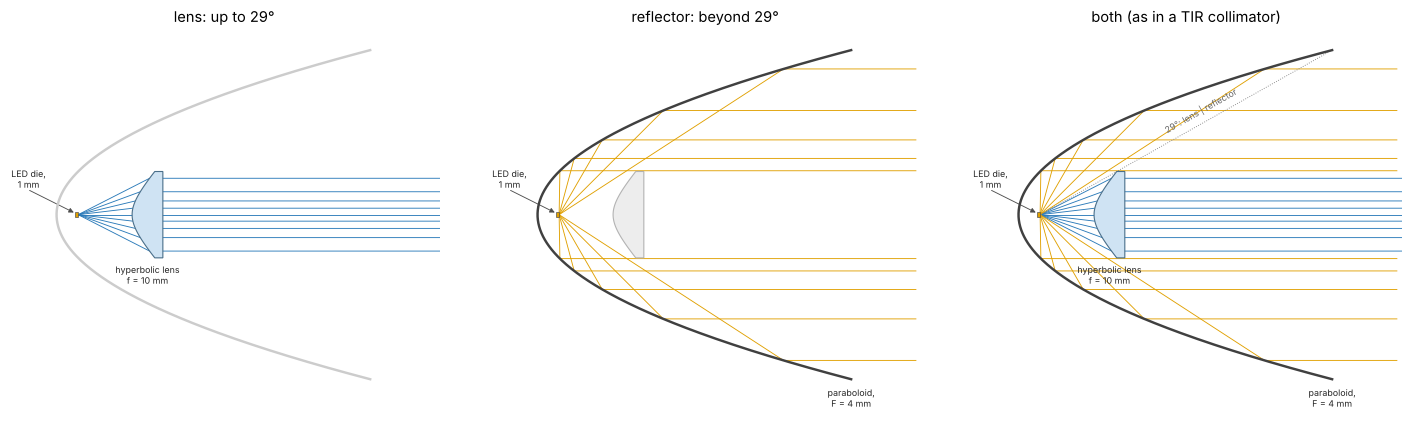

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), layout="constrained")
for a, kind, t in zip(ax, ("lens", "reflector", "hybrid"), ("lens: up to 29°", "reflector: beyond 29°", "both (as in a TIR collimator)")):
    sketch.led_collimator(a, kind, title=t)
plt.show()

In [13]:
F_L, N_G, A_L, F_P, W_DIE = 10.0, 1.5, 8.0, 4.0, 1.0      # mm
R_L, K_L = (N_G - 1)*F_L, -N_G**2                            # hyperbolic surface: stigmatic for the die centre
sag_L = A_L**2/R_L/(1 + np.sqrt(1 - (1 + K_L)*A_L**2/R_L**2))
lens = rt.System([rt.Surface(R_L, sag_L + 1.5, n_after=N_G, semi_diameter=A_L, conic=K_L),
                  rt.Surface(np.inf, 50.0, n_after=1.0, semi_diameter=A_L)],
                 0, 550e-6, object_distance=F_L, object_height=W_DIE/2)
theta_L = np.arctan(A_L/(F_L + sag_L))
rho_rim = 2*F_P/(1 - np.cos(theta_L))
z_rim, r_rim = rho_rim*np.cos(theta_L), rho_rim*np.sin(theta_L)
print("lens: semi-diameter {:.0f} mm, collects up to {:.1f} deg, sin^2 = {:.3f} of a Lambertian LED".format(A_L, np.degrees(theta_L), np.sin(theta_L)**2))
print("paraboloid F = {:.0f} mm from 90 deg down to {:.1f} deg: rim at z = {:.1f} mm, radius {:.1f} mm".format(F_P, np.degrees(theta_L), z_rim, r_rim))
N5 = 2_000_000
P5 = np.column_stack([(rng.random((N5, 2)) - 0.5)*W_DIE, np.zeros(N5)])
d5 = il.lambertian_directions(N5, rng=rng)
B5 = lens.trace(rt.Rays(P5 - [0, 0, F_L], d5, np.zeros(N5)))
D_lens = B5.directions[-1]
P_lens = B5.points[-1]
in_lens = np.isfinite(D_lens[:, 2])
Q_ref, D_ref, hit = il.paraboloid_reflector(P5[~in_lens], d5[~in_lens], F_P, z_max=z_rim)
L5 = PHI/(np.pi*W_DIE**2)                                     # lm/(mm^2 sr)
I_bare = PHI/np.pi
print("die {0} x {0} mm, 100 lm: radiance {1:.1f} cd/mm^2, bare LED on axis {2:.1f} cd".format(W_DIE, L5, I_bare))
edges5 = np.deg2rad(np.linspace(0, 8, 81))
prof = {}
peak = {}
D_all = np.concatenate([D_lens[in_lens], D_ref[hit]])
for name, D in (("lens", D_lens[in_lens]), ("reflector", D_ref[hit]), ("hybrid", D_all)):
    prof[name] = il.intensity_profile(D, PHI/N5, edges5)
    peak[name] = il.intensity_profile(D, PHI/N5, np.deg2rad([0, 0.3]))[0][0]   # mean within 0.3 deg
    I, th = prof[name]
    half = np.degrees(th[np.where(I >= peak[name]/2)[0].max()])
    print("{:9s}: efficiency {:.3f}, peak (mean within 0.3 deg) {:6.0f} cd = {:4.0f} x the bare LED, "
          "half angle at half maximum {:.2f} deg".format(name, len(D)/N5, peak[name], peak[name]/I_bare, half))
print("brightness bound L x exit area: lens {:.0f} cd, hybrid {:.0f} cd; reached {:.1%} and {:.1%}".format(
    L5*np.pi*A_L**2, L5*np.pi*r_rim**2, peak["lens"]/(L5*np.pi*A_L**2), peak["hybrid"]/(L5*np.pi*r_rim**2)))
print("die half width over focal length: lens {:.2f} deg, paraboloid {:.2f} to {:.2f} deg".format(
    np.degrees(np.arctan(W_DIE/2/F_L)), np.degrees(np.arctan(W_DIE/2/rho_rim)), np.degrees(np.arctan(W_DIE/2/(2*F_P)))))
# the spot on a wall 5 m away
Z_WALL = 5000.0
def to_wall(P, D):
    return P[:, :2] + D[:, :2]/D[:, 2:3]*(Z_WALL - P[:, 2:3])
wall = {"lens": to_wall(P_lens[in_lens] + [0, 0, F_L], D_lens[in_lens]),
        "reflector": to_wall(Q_ref[hit], D_ref[hit])}
E_wall = {k: il.irradiance_map(v/1000, PHI/N5, 150, [(-0.6, 0.6)]*2) for k, v in wall.items()}   # m, lux
# where does the inverse square law start to hold for the collimated beam?
P_exit = np.concatenate([P_lens[in_lens] + [0, 0, F_L], Q_ref[hit]])
D_exit = np.concatenate([D_lens[in_lens], D_ref[hit]])
walls = np.array([1, 2, 5, 10, 20, 50, 100])*1000.0      # mm
E_d2 = []
for zw in walls:
    XY = P_exit[:, :2] + D_exit[:, :2]/D_exit[:, 2:3]*(zw - P_exit[:, 2:3])
    r0 = zw*np.tan(np.deg2rad(0.3))
    E_c = np.sum(np.hypot(XY[:, 0], XY[:, 1]) < r0)*PHI/N5/(np.pi*r0**2)    # lm/mm^2, mean within 0.3 deg
    E_d2.append(E_c*zw**2)
E_d2 = np.array(E_d2)
for zw, e in zip(walls, E_d2):
    print("wall at {:5.0f} m: centre illuminance {:8.0f} lux, E d^2 = {:6.0f} cd ({:.0%} of the far-field peak)".format(
        zw/1000, e/zw**2*1e6, e, e/peak["hybrid"]))
print("exit diameter over beam half angle: {:.1f} m".format(2*r_rim/np.tan(np.deg2rad(0.75))/1000))

lens: semi-diameter 8 mm, collects up to 29.4 deg, sin^2 = 0.241 of a Lambertian LED
paraboloid F = 4 mm from 90 deg down to 29.4 deg: rim at z = 54.1 mm, radius 30.5 mm


die 1.0 x 1.0 mm, 100 lm: radiance 31.8 cd/mm^2, bare LED on axis 31.8 cd
lens     : efficiency 0.240, peak (mean within 0.3 deg)   6441 cd =  202 x the bare LED, half angle at half maximum 1.75 deg


reflector: efficiency 0.755, peak (mean within 0.3 deg)  85036 cd = 2671 x the bare LED, half angle at half maximum 0.75 deg


hybrid   : efficiency 0.996, peak (mean within 0.3 deg)  91477 cd = 2874 x the bare LED, half angle at half maximum 0.75 deg
brightness bound L x exit area: lens 6400 cd, hybrid 92988 cd; reached 100.6% and 98.4%
die half width over focal length: lens 2.86 deg, paraboloid 0.46 to 3.58 deg


wall at     1 m: centre illuminance    23026 lux, E d^2 =  23026 cd (25% of the far-field peak)
wall at     2 m: centre illuminance    13523 lux, E d^2 =  54091 cd (59% of the far-field peak)
wall at     5 m: centre illuminance     3439 lux, E d^2 =  85969 cd (94% of the far-field peak)
wall at    10 m: centre illuminance      902 lux, E d^2 =  90206 cd (99% of the far-field peak)
wall at    20 m: centre illuminance      228 lux, E d^2 =  91024 cd (100% of the far-field peak)
wall at    50 m: centre illuminance       37 lux, E d^2 =  91347 cd (100% of the far-field peak)
wall at   100 m: centre illuminance        9 lux, E d^2 =  91420 cd (100% of the far-field peak)
exit diameter over beam half angle: 4.7 m


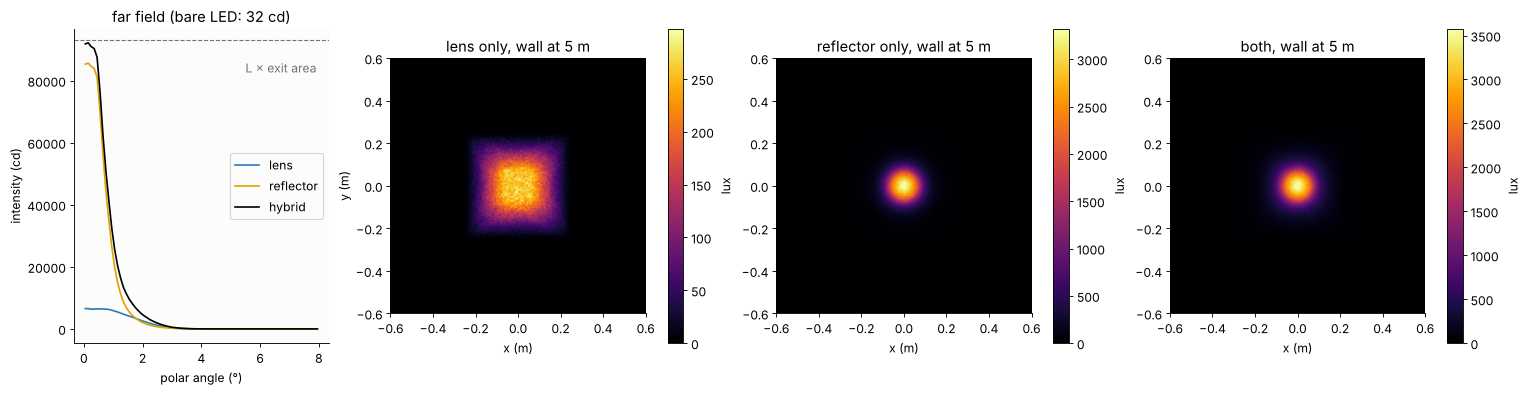

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4.8), layout="constrained")
for name, c in (("lens", BLUE), ("reflector", ORANGE), ("hybrid", "k")):
    I, th = prof[name]
    ax[0].plot(np.degrees(th), I, color=c, label=name)
ax[0].axhline(L5*np.pi*r_rim**2, color=GREY, ls="--", lw=1)
ax[0].text(5.5, L5*np.pi*r_rim**2*0.93, "L × exit area", color=GREY, va="top")
ax[0].set_xlabel("polar angle (°)")
ax[0].set_ylabel("intensity (cd)")
ax[0].set_title("far field (bare LED: {:.0f} cd)".format(I_bare))
ax[0].legend()
for a, name in zip(ax[1:3], ("lens", "reflector")):
    E, x, y = E_wall[name]
    im = a.imshow(E.T, extent=[-0.6, 0.6, -0.6, 0.6], origin="lower", cmap="inferno")
    fig.colorbar(im, ax=a, label="lux")
    a.set_title("{} only, wall at 5 m".format(name))
    a.set_xlabel("x (m)")
ax[1].set_ylabel("y (m)")
E_sum = E_wall["lens"][0] + E_wall["reflector"][0]
im = ax[3].imshow(E_sum.T, extent=[-0.6, 0.6, -0.6, 0.6], origin="lower", cmap="inferno")
fig.colorbar(im, ax=ax[3], label="lux")
ax[3].set_title("both, wall at 5 m")
ax[3].set_xlabel("x (m)")
plt.show()

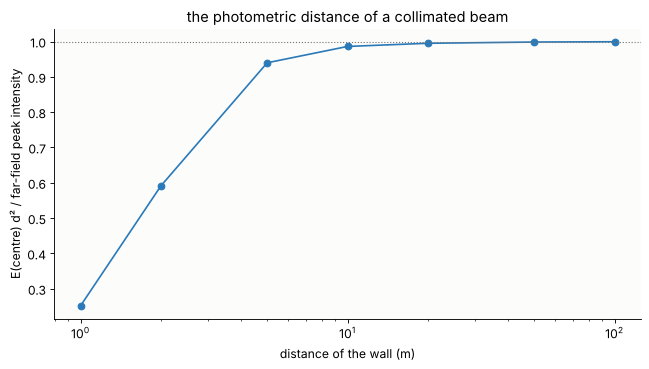

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
ax.semilogx(walls/1000, E_d2/peak["hybrid"], "o-", color=BLUE)
ax.axhline(1, color=GREY, ls=":", lw=1)
ax.set_xlabel("distance of the wall (m)")
ax.set_ylabel("E(centre) d² / far-field peak intensity")
ax.set_title("the photometric distance of a collimated beam")
plt.show()

The numbers:

| | collected flux | peak intensity | over bare LED | brightness bound $LA$ |
|---|---|---|---|---|
| lens | 24.0 % | 6441 cd | 202 × | 6400 cd |
| reflector | 75.5 % | 85 036 cd | 2671 × | |
| both | 99.6 % | 91 477 cd | 2874 × | 92 988 cd |

- **The brightness bound holds and is reached.** The stigmatic lens fills
  its aperture with the die's radiance (100.6 % of $LA$, within the 1 %
  Monte Carlo noise), and the hybrid reaches 98.4 %. Only the exit area
  counts: to double the peak intensity of a given LED, double the
  aperture area.
- **Collection.** The lens alone gets a quarter of the flux. The
  reflector does most of the work because a Lambertian LED puts three
  quarters of its light beyond 29°.
- **Beam shape.** Each part of the optics forms an image of the die in
  the far field. Its size is set by the distance from the die to that
  part: $w/f$ = 2.9° for the lens, and from 3.6° (near the vertex) down to
  0.46° (at the rim) for the paraboloid. The lens makes a square spot. The
  reflector adds die images of many sizes into a peaked beam, half
  maximum at 0.75°, without corners.
- **Photometric distance of a beam.** The far-field intensity only
  appears far away: at the distance of the exit diameter divided by the
  beam angle, here 61 mm/0.013 rad ≈ 4.7 m. At 1 m the centre illuminance
  is only 25 % of $I/d^2$, at 2 m 59 %, at 5 m 94 % and at 10 m 99 %.
  Five *exit* diameters (30 cm) are nowhere near enough for a collimated
  beam.

The square die image of the lens is the usual reason why spotlights add a
diffuser or a lenslet array (notebook 86): it trades a little intensity
for a smooth spot.

## Summary

- LED patterns $I_0\cos^m\theta$ with $m = -\ln2/\ln\cos\theta_{1/2}$
  and $\Phi = 2\pi I_0/(m+1)$, sampled by $\cos\theta = u^{1/(m+1)}$ and
  measured by binning directions into rings of solid angle.
- On a plane, $E = I_0\cos^{m+3}\theta/h^2$. The Monte Carlo error of a
  bin is $1/\sqrt n$ for $n$ rays, and bins trade this noise against a
  bias from averaging the curvature. Scrambled Sobol rays converge as
  $N^{-3/4}$ instead of $N^{-1/2}$.
- The inverse square law is 1 % off at five source diameters
  ($a^2/d^2$). For a collimated beam, the source is the exit aperture, and
  the far field starts only at diameter over beam angle.
- Two LEDs are flattest at $d = 2h/\sqrt{m + 4}$. Large square arrays
  stay within 10 % up to $d = 1.15h$ (Lambertian), and the edges of finite
  arrays fall off.
- A lens collects $\sin^2\theta$ of a Lambertian LED and a paraboloid the
  rest. Together they reach the brightness bound $I = L A_\mathrm{exit}$,
  here 2900 times the bare LED. The beam angle is die size over focal
  length.

In [16]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 21 s


## References

- I. Moreno, M. Avendaño-Alejo and R. I. Tzonchev, "Designing
  light-emitting diode arrays for uniform near-field irradiance", Appl.
  Opt. 45, 2265–2272 (2006).
- J. Chaves, *Introduction to Nonimaging Optics*, 2nd ed., CRC Press
  (2016).
- R. Winston, J. C. Miñano and P. Benítez, *Nonimaging Optics*, Elsevier
  (2005).
- A. B. Owen, *Monte Carlo Theory, Methods and Examples* (2013), on
  quasi-Monte Carlo and scrambled Sobol sequences.
- I. M. Sobol', "On the distribution of points in a cube and the
  approximate evaluation of integrals", USSR Comput. Math. Math. Phys. 7,
  86–112 (1967).